# ***Superstore Profitability Analysis***


**This project analyzes the sales and profitability performance of a retail company using the Sample Superstore dataset.
The main objective is to identify the key drivers of profit and uncover areas of underperformance in order to provide actionable business recommendations.**

### Dataset
- **Period**: 2014 – 2017
- **Records**: 9,994 order lines
- **Orders**: 5,009
- **Total Sales**: $2,297,201

- **Total Profit**: $286,397 (12.5% margin)

### Business Questions
1. How has sales and profit evolved over the years?
2. Which product categories are the most and least profitable?
3. Which individual products generate the highest profits and the largest losses?
4. What is the impact of discounts on profitability?
5. How do customer segments and regions perform in terms of profit?

### Approach
The analysis combines descriptive statistics, profitability metrics (profit margin), and data visualizations to evaluate performance across multiple dimensions: time, category, product, discount, customer, and region.

In [547]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


In [548]:
df = pd.read_csv("Sample - Superstore.csv", encoding="cp1252")
print("Shape:", df.shape)

df.head()

Shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [549]:
print(f"{len(df):,} order lines, {df['Order ID'].nunique():,} orders, total sales {df['Sales'].sum():,.0f}, "
      f"profit {df['Profit'].sum():,.0f} ({df['Profit'].sum() / df['Sales'].sum():.1%} margin)")

9,994 order lines, 5,009 orders, total sales 2,297,201, profit 286,397 (12.5% margin)


In [550]:

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
print(df.dtypes)
print(df.nunique())


Rows: 9994
Columns: 21
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64
Duplicates: 0
Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object
Row ID      

In [551]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [552]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [553]:
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

In [554]:
df["Order Date"] = pd.to_datetime(df["Order Date"])

In [555]:
df["Order Date"].dtype

dtype('<M8[ns]')

In [556]:
df["Order Date"].dt.year.value_counts().sort_index()

,count
Order Date,
2014,1993
2015,2102
2016,2587
2017,3312


In [557]:
df["Postal Code"] = df["Postal Code"].astype(str)

In [558]:

# Check negative sales
print("Negative Sales:", (df["Sales"] < 0).sum())

# Check negative quantities
print("Negative Quantity:", (df["Quantity"] < 0).sum())

# Check discounts outside [0, 1]
print("Invalid Discounts:",
      ((df["Discount"] < 0) |
       (df["Discount"] > 1)).sum())

# Check shipping dates before order dates
order_date = pd.to_datetime(df["Order Date"])
ship_date = pd.to_datetime(df["Ship Date"])

print("Invalid shipping chronology:",
      (ship_date < order_date).sum())


Negative Sales: 0
Negative Quantity: 0
Invalid Discounts: 0
Invalid shipping chronology: 0


In [559]:
df.groupby(df["Order Date"].dt.year)["Sales"].sum()

,Sales
Order Date,
2014,484247.4981
2015,470532.5090
2016,609205.5980
2017,733215.2552


In [560]:
df.groupby("Category")["Sales"].sum().sort_values(ascending=False)

,Sales
Category,
Technology,836154.0330
Furniture,741999.7953
Office Supplies,719047.0320


<Axes: title={'center': ' Total Sales by Category'}, xlabel='Category', ylabel='Total Sales'>

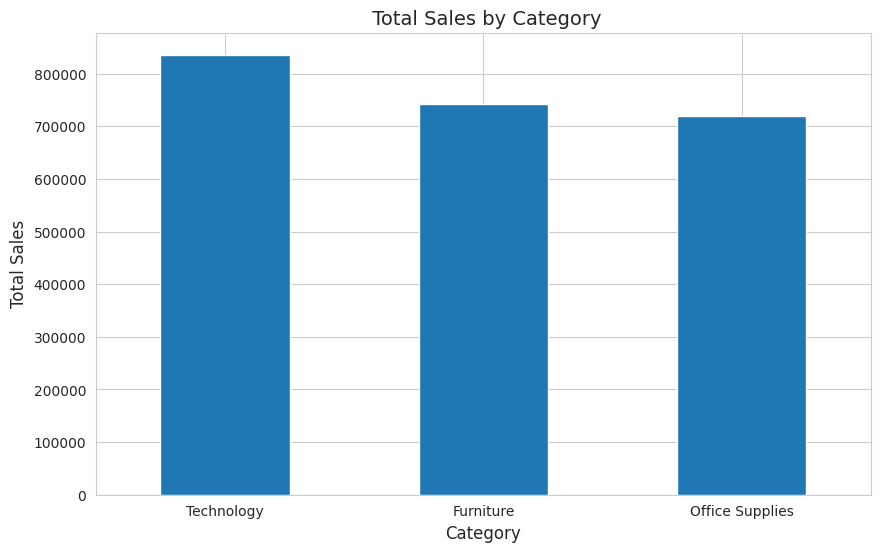

In [561]:
sales_category= df.groupby("Category")["Sales"].sum().sort_values(ascending=False)

sales_category.plot(
    kind="bar" ,
    title=" Total Sales by Category" ,
    xlabel="Category" ,
    ylabel="Total Sales" ,
    rot=0 ,
    figsize=(10,6)
)

In [562]:
df.groupby("Category")["Profit"].sum().sort_values(ascending=False)

,Profit
Category,
Technology,145454.9481
Office Supplies,122490.8008
Furniture,18451.2728


**Technology leads both in total sales and total profit. However, Furniture generates considerably less profit despite having the second-highest sales, suggesting a potential profitability issue that deserves further investigation.**

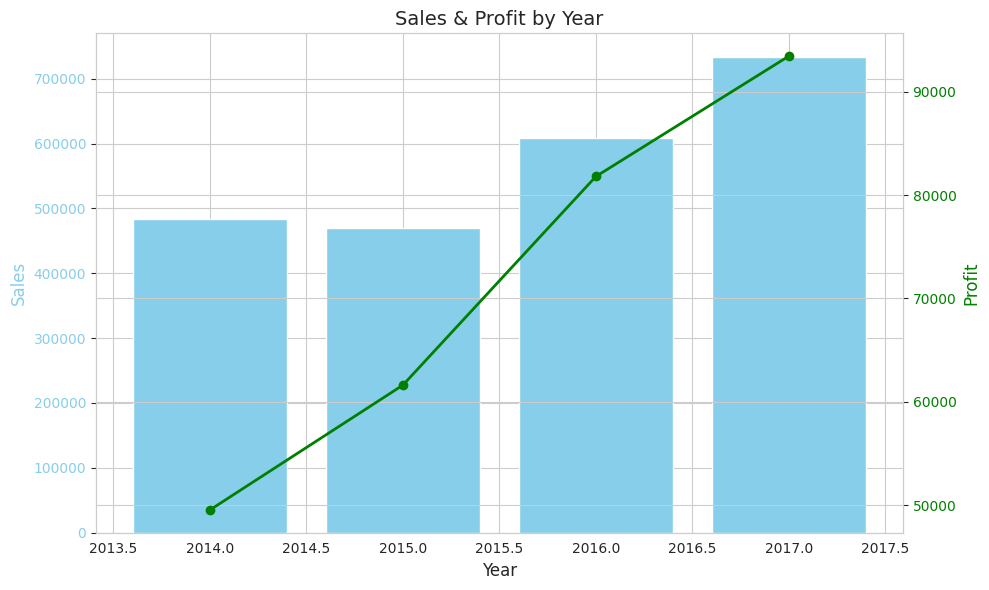

In [563]:
yearly = df.groupby(df["Order Date"].dt.year).agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
).reset_index()

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.bar(yearly["Order Date"], yearly["Sales"], color="skyblue", label="Sales")
ax1.set_xlabel("Year")
ax1.set_ylabel("Sales", color="skyblue")
ax1.tick_params(axis="y", labelcolor="skyblue")

ax2 = ax1.twinx()
ax2.plot(yearly["Order Date"], yearly["Profit"], color="green", marker="o", linewidth=2, label="Profit")
ax2.set_ylabel("Profit", color="green")
ax2.tick_params(axis="y", labelcolor="green")

plt.title("Sales & Profit by Year")
fig.tight_layout()
plt.show()

Sales show consistent growth from 2014 to 2017, reaching their highest level in 2017.
Profit also increased over the years, although the growth was less linear than sales.
This indicates that while the business is expanding, profitability is not improving at the same pace.

In [564]:
df.groupby("Category")[["Discount", "Profit"]].mean()

,Discount,Profit
Category,,
Furniture,0.173923,8.699327
Office Supplies,0.157285,20.327050
Technology,0.132323,78.752002


In [565]:
df[["Discount", "Profit"]].corr()

,Discount,Profit
Discount,1.000000,-0.219487
Profit,-0.219487,1.000000


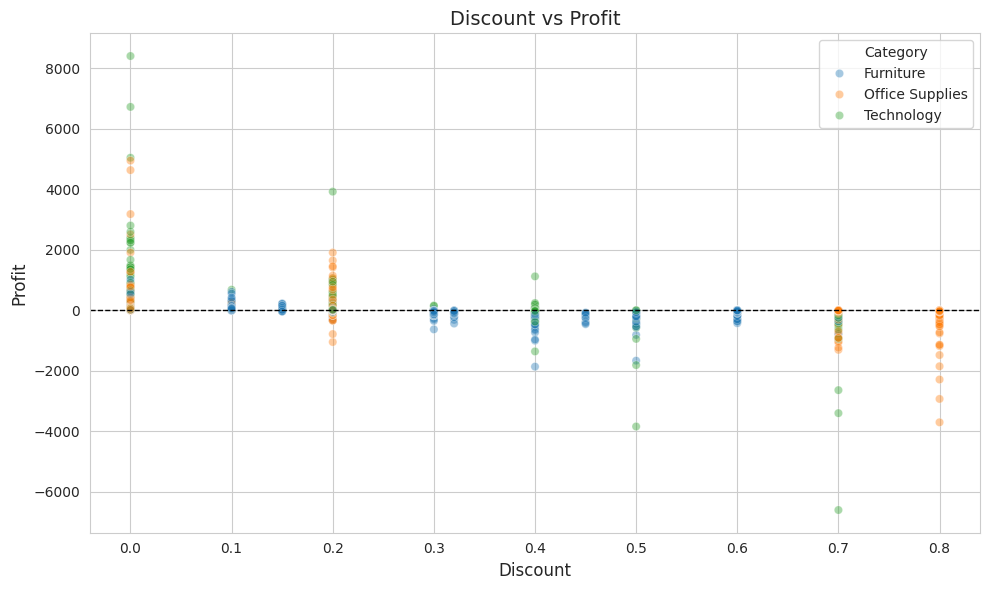

In [566]:

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="Discount", y="Profit", alpha=0.4, hue="Category")
plt.title("Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.legend(title="Category")
plt.tight_layout()
plt.show()

There is a weak negative correlation was observed between discount and profit.
Higher discounts, especially above 20-30%, are frequently associated with losses,
particularly in the Furniture category. Discount policies should be reviewed carefully.*texte en italique*

In [567]:
correlation_by_category = df.groupby("Category").apply(
    lambda x: x["Discount"].corr(x["Profit"]),
    include_groups=False
)

correlation_by_category

,0
Category,
Furniture,-0.483769
Office Supplies,-0.208787
Technology,-0.268853


**Furniture has the strongest negative correlation between Discount and Profit (-0.484), suggesting that higher discounts are more closely associated with lower profits in this category.**

In [568]:
furniture = df[df["Category"] == "Furniture"]

In [569]:
furniture.groupby("Discount")["Profit"].mean().sort_index()

,Profit
Discount,
0.00,69.537173
0.10,93.565946
0.15,27.288298
0.20,10.188535
0.30,-48.177103
0.32,-88.560656
0.40,-215.831957
0.45,-226.646464
0.50,-238.355537


<Axes: title={'center': 'Average Profit by Discount - Furniture'}, xlabel='Discount', ylabel='Average Profit'>

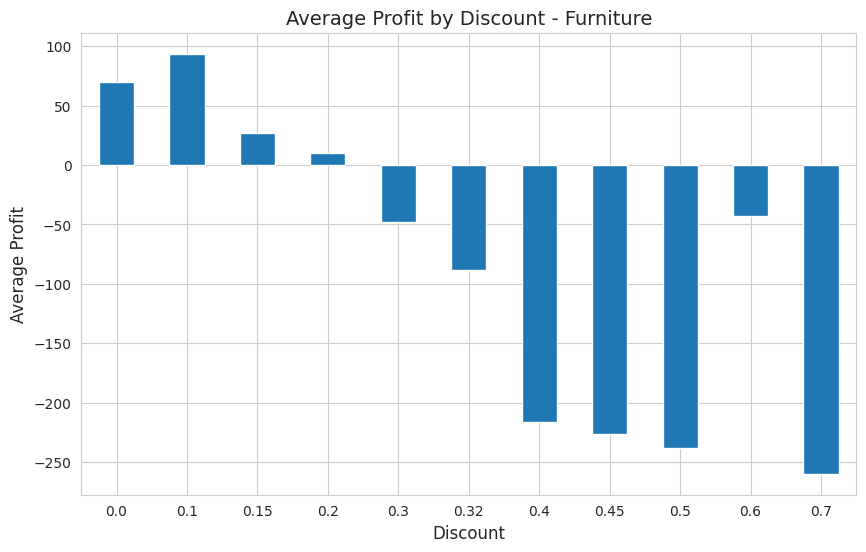

In [570]:
furniture.groupby("Discount")["Profit"].mean().plot(
    kind="bar",
    title="Average Profit by Discount - Furniture",
    xlabel="Discount",
    ylabel="Average Profit",
    figsize=(10,6),
    rot=0
)

**In the Furniture category, average profit becomes negative at discount levels of 30% and above in most observed cases. High discounts are associated with substantial losses, suggesting that discount strategies should be reviewed carefully.**

In [571]:
furniture.groupby("Discount")["Profit"].agg(["count", "mean", "sum"])

,count,mean,sum
Discount,,,
0.00,836,69.537173,58133.0764
0.10,76,93.565946,7111.0119
0.15,52,27.288298,1418.9915
0.20,615,10.188535,6265.9491
0.30,222,-48.177103,-10695.3169
0.32,27,-88.560656,-2391.1377
0.40,75,-215.831957,-16187.3968
0.45,11,-226.646464,-2493.1111
0.50,54,-238.355537,-12871.1990


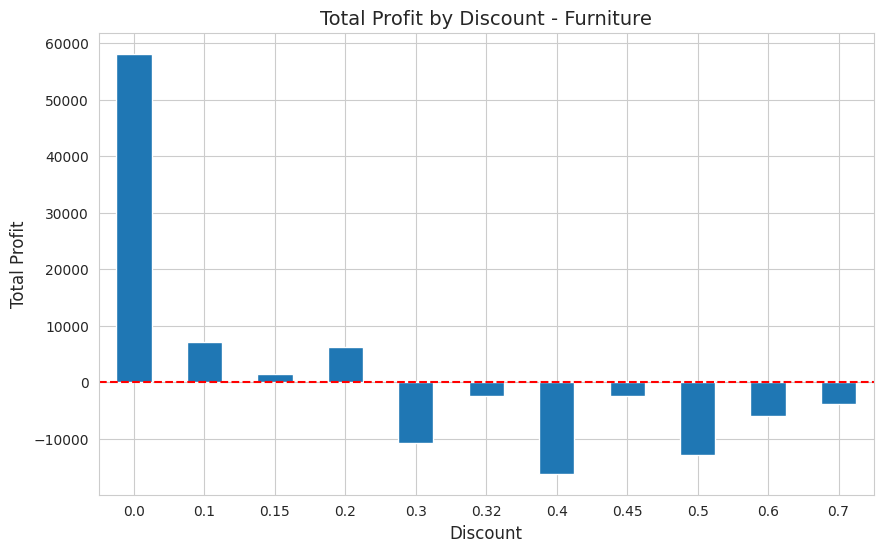

In [572]:
furniture.groupby("Discount")["Profit"].sum().plot(
    kind="bar",
    title="Total Profit by Discount - Furniture",
    xlabel="Discount",
    ylabel="Total Profit",
    figsize=(10,6),
    rot=0
)

plt.axhline(y=0, color="red", linestyle="--")
plt.show()

**Profit by sub-category**

In [573]:
furniture_analysis = furniture.groupby("Sub-Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Number_of_Orders=("Order ID", "nunique")
)

furniture_analysis["Profit_Margin"] = (
    furniture_analysis["Total_Profit"] /
    furniture_analysis["Total_Sales"]
) * 100

furniture_analysis.sort_values(
    by="Total_Profit",
    ascending=True
)

,Total_Sales,Total_Profit,Number_of_Orders,Profit_Margin
Sub-Category,,,,
Tables,206965.5320,-17725.4811,307,-8.564460
Bookcases,114879.9963,-3472.5560,224,-3.022768
Furnishings,91705.1640,13059.1436,877,14.240358
Chairs,328449.1030,26590.1663,576,8.095673


In [574]:
tables = furniture[furniture["Sub-Category"] == "Tables"]

tables.groupby("Discount")["Profit"].agg(
    ["count", "mean", "sum"]
).sort_index()

,count,mean,sum
Discount,,,
0.00,72,184.393051,13276.2997
0.20,71,-4.275465,-303.5580
0.30,54,-63.006067,-3402.3276
0.40,75,-215.831957,-16187.3968
0.45,11,-226.646464,-2493.1111
0.50,36,-239.316314,-8615.3873


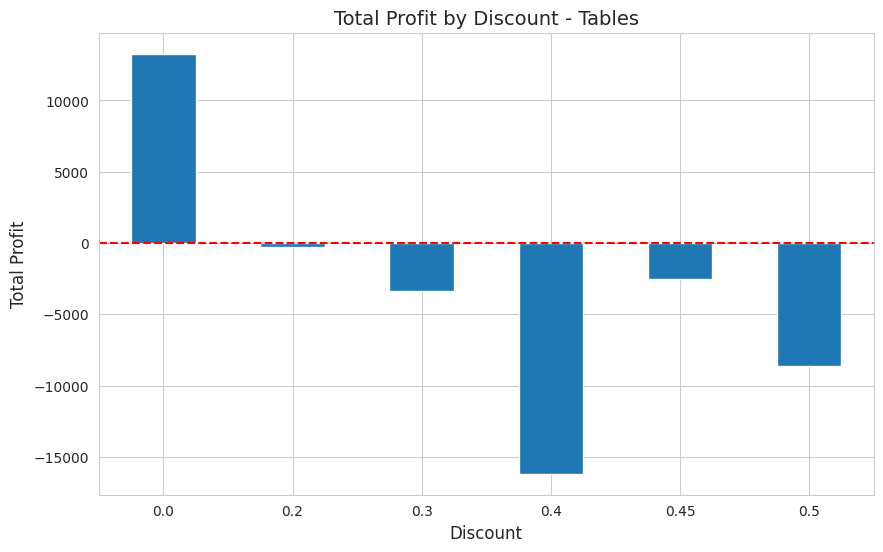

In [575]:
tables.groupby("Discount")["Profit"].sum().plot(
    kind="bar",
    title="Total Profit by Discount - Tables",
    xlabel="Discount",
    ylabel="Total Profit",
    figsize=(10, 6),
    rot=0
)

plt.axhline(y=0, color="red", linestyle="--")
plt.show()

**The results show that high discounts are associated with lower profits. The 40% discount has the highest total loss, while the 50% discount has the lowest average profit.**

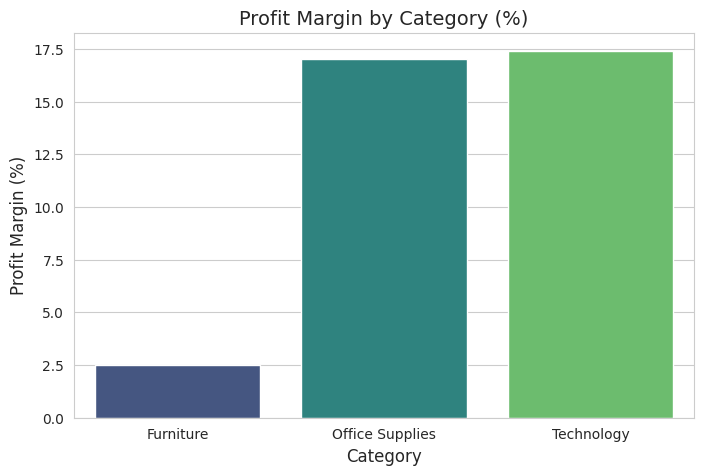

In [576]:

category_summary = df.groupby("Category").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
)
category_summary["Profit_Margin"] = (category_summary["Profit"] / category_summary["Sales"]) * 100

plt.figure(figsize=(8, 5))
sns.barplot(
    x=category_summary.index,
    y=category_summary["Profit_Margin"],
    hue=category_summary.index,
    palette="viridis",
    legend=False
)
plt.title("Profit Margin by Category (%)")
plt.ylabel("Profit Margin (%)")
plt.xlabel("Category")
plt.show()

Technology and Office Supplies achieve healthy profit margins (around 17%),
while Furniture records a very low margin of only 2.5%.
This highlights a clear profitability issue in the Furniture category that requires further investigation.

**Sales & Profit by Region**

In [577]:
region_analysis = df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
)
region_analysis
region_analysis["Profit_Margin"] = (
    region_analysis["Total_Profit"] /
    region_analysis["Total_Sales"]
) * 100

region_analysis.sort_values(
    by="Total_Profit",
    ascending=False
)


,Total_Sales,Total_Profit,Profit_Margin
Region,,,
West,725457.8245,108418.4489,14.944831
East,678781.2400,91522.7800,13.483399
South,391721.9050,46749.4303,11.934342
Central,501239.8908,39706.3625,7.921629


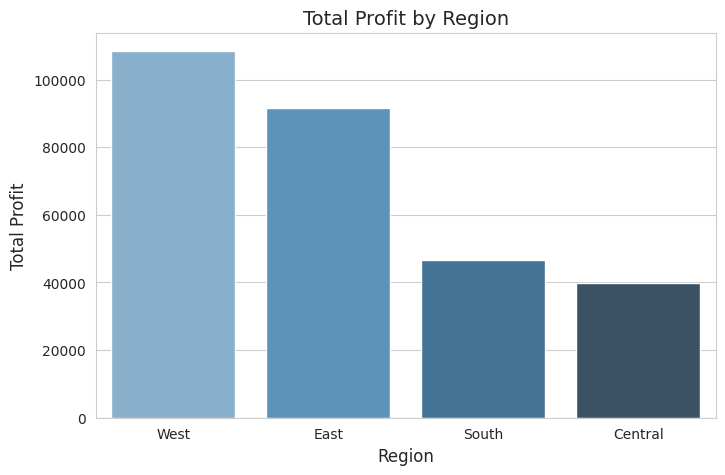

In [578]:

region_profit = df.groupby("Region")["Profit"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(
    x=region_profit.index,
    y=region_profit.values,
    hue=region_profit.index,
    palette="Blues_d",
    legend=False
)
plt.title("Total Profit by Region")
plt.ylabel("Total Profit")
plt.xlabel("Region")
plt.show()

The West region generates the highest total profit,
while the Central region underperforms.
Focusing on improving profitability in the Central region represents a clear opportunity.

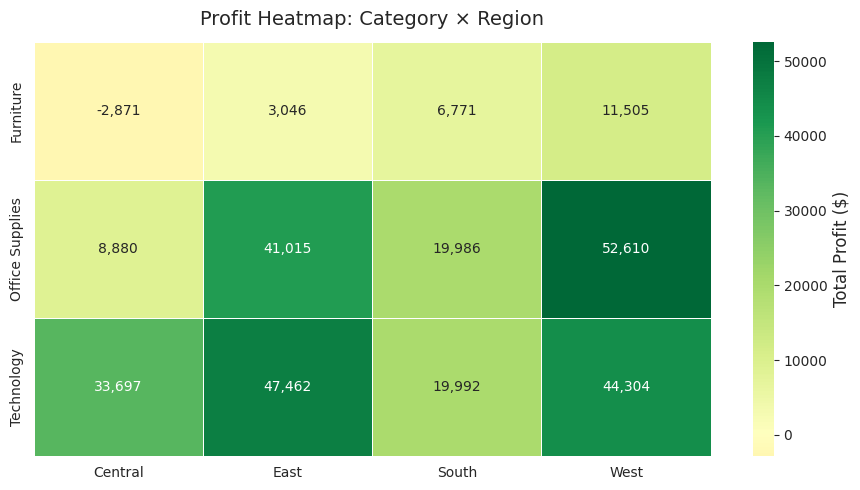

In [579]:

pivot = df.pivot_table(values="Profit", index="Category", columns="Region", aggfunc="sum")

plt.figure(figsize=(9, 5))
sns.heatmap(pivot, annot=True, fmt=",.0f", cmap="RdYlGn", center=0,
            linewidths=0.5, linecolor="white",
            cbar_kws={'label': 'Total Profit ($)'})

plt.title("Profit Heatmap: Category × Region", fontsize=14, pad=12)
plt.ylabel("")
plt.xlabel("")
plt.tight_layout()
plt.show()

The heatmap confirms that Technology performs well across most regions,
while Furniture shows weak or negative profit in several areas.
The combination of Furniture + Central region appears particularly problematic.

**Sales by Segment**

In [580]:
segment_analysis = df.groupby("Segment").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Number_of_Orders=("Order ID", "nunique")
)

segment_analysis
segment_analysis["Profit_Margin"] = (
    segment_analysis["Total_Profit"] /
    segment_analysis["Total_Sales"]
) * 100

segment_analysis.sort_values(
    by="Profit_Margin",
    ascending=False
)

,Total_Sales,Total_Profit,Number_of_Orders,Profit_Margin
Segment,,,,
Home Office,4.296531e+05,60298.6785,909,14.034269
Corporate,7.061464e+05,91979.1340,1514,13.025506
Consumer,1.161401e+06,134119.2092,2586,11.548050


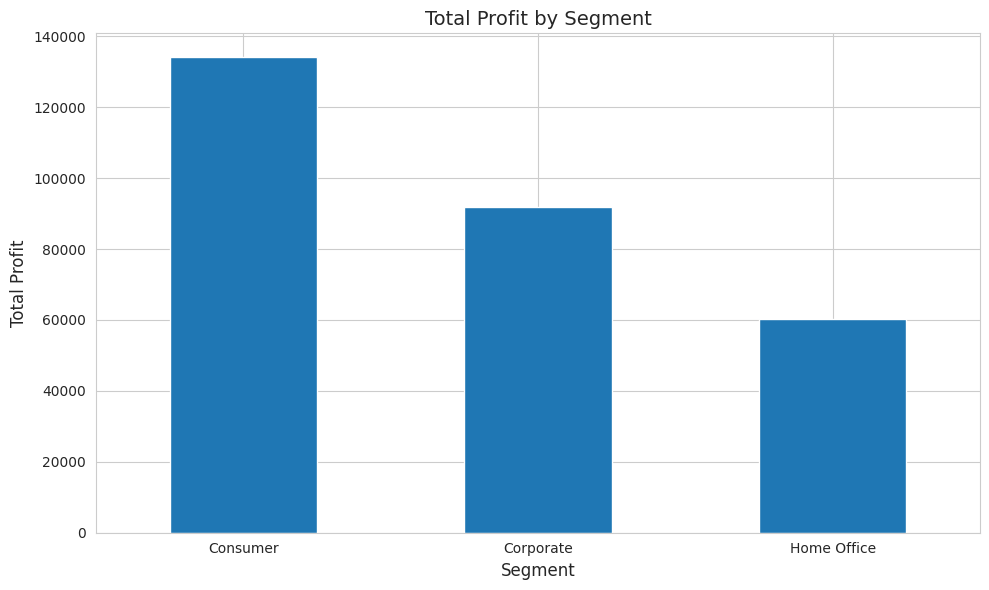

In [581]:
segment_analysis["Total_Profit"].plot(
    kind="bar",
    title="Total Profit by Segment",
    xlabel="Segment",
    ylabel="Total Profit",
    figsize=(10, 6),
    rot=0
)

plt.tight_layout()
plt.show()

**The Consumer segment generates the highest total profit, followed by Corporate and Home Office.**

**Customer Analysis**

In [582]:
customer_analysis = df.groupby("Customer Name").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Number_of_Orders=("Order ID", "nunique")
)

customer_analysis.sort_values(
    by="Total_Profit",
    ascending=False
).head(10)
customer_analysis["Profit_Margin"] = (
    customer_analysis["Total_Profit"] /
    customer_analysis["Total_Sales"]
) * 100

customer_analysis.sort_values(
    by="Profit_Margin",
    ascending=False
).head(10)

,Total_Sales,Total_Profit,Number_of_Orders,Profit_Margin
Customer Name,,,,
Jenna Caffey,1058.108,502.9244,1,47.530536
Tamara Chand,19052.218,8981.3239,5,47.140569
Raymond Buch,15117.339,6976.0959,6,46.146322
Steven Roelle,4345.886,1990.4244,8,45.800198
Bobby Odegard,130.830,59.4522,2,45.442330
Hunter Lopez,12873.298,5622.4292,6,43.675127
Andy Reiter,6608.448,2884.6208,6,43.650503
Christopher Martinez,8954.020,3899.8904,4,43.554631
Ivan Gibson,744.574,320.4982,4,43.044506


In [583]:
sean_orders = df[df["Customer Name"] == "Sean Miller"]

sean_analysis = sean_orders.groupby("Product Name").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Discount=("Discount", "mean"),
    Number_of_Orders=("Order ID", "nunique")
)

sean_analysis.sort_values(
    by="Total_Profit",
    ascending=True
)

,Total_Sales,Total_Profit,Average_Discount,Number_of_Orders
Product Name,,,,
Cisco TelePresence System EX90 Videoconferencing Unit,22638.480,-1811.0784,0.5,1
"SAFCO Commercial Wire Shelving, Black",663.072,-165.7680,0.2,1
GBC DocuBind P100 Manual Binding Machine,99.588,-82.9900,0.7,1
Hewlett-Packard Deskjet 6540 Color Inkjet Printer,821.300,-16.4260,0.5,1
Staple remover,3.488,-0.6976,0.2,1
Avery Fluorescent Highlighter Four-Color Set,8.016,1.0020,0.2,1
Xerox 1989,7.968,2.6892,0.2,1
Sabrent 4-Port USB 2.0 Hub,21.728,3.8024,0.2,1
Xerox 1949,9.960,4.8804,0.0,1


In [584]:
df[df["Product Name"] == "Cisco TelePresence System EX90 Videoconferencing Unit"][
    ["Customer Name", "Sales", "Quantity", "Discount", "Profit"]
]

,Customer Name,Sales,Quantity,Discount,Profit
2697,Sean Miller,22638.48,6,0.5,-1811.0784


**I recommend reviewing the discount rate for this product to reduce potential losses, rather than stopping its sales completely.**

**Product Profitability Analysis**

In [585]:
product_analysis = df.groupby("Product Name").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Number_of_Orders=("Order ID", "nunique")
)
product_analysis.sort_values(
    by="Total_Profit",
    ascending=False
).head(10)

,Total_Sales,Total_Profit,Total_Quantity,Number_of_Orders
Product Name,,,,
Canon imageCLASS 2200 Advanced Copier,61599.824,25199.9280,20,5
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.384,7753.0390,31,10
Hewlett Packard LaserJet 3310 Copier,18839.686,6983.8836,38,8
Canon PC1060 Personal Laser Copier,11619.834,4570.9347,19,4
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.895,4094.9766,12,3
Ativa V4110MDD Micro-Cut Shredder,7699.890,3772.9461,11,2
"3D Systems Cube Printer, 2nd Generation, Magenta",14299.890,3717.9714,11,2
Plantronics Savi W720 Multi-Device Wireless Headset System,9367.290,3696.2820,24,7
Ibico EPK-21 Electric Binding System,15875.916,3345.2823,13,3


In [586]:
(product_analysis["Total_Profit"] < 0).sum()

np.int64(301)

In [587]:
product_analysis.sort_values(
    by="Total_Profit",
    ascending=True
).head(10)

,Total_Sales,Total_Profit,Total_Quantity,Number_of_Orders
Product Name,,,,
Cubify CubeX 3D Printer Double Head Print,11099.963,-8879.9704,9,3
Lexmark MX611dhe Monochrome Laser Printer,16829.901,-4589.9730,18,4
Cubify CubeX 3D Printer Triple Head Print,7999.980,-3839.9904,4,1
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,9917.640,-2876.1156,27,5
Bush Advantage Collection Racetrack Conference Table,9544.725,-1934.3976,33,7
GBC DocuBind P400 Electric Binding System,17965.068,-1878.1662,27,6
Cisco TelePresence System EX90 Videoconferencing Unit,22638.480,-1811.0784,6,1
Martin Yale Chadless Opener Electric Letter Opener,16656.200,-1299.1836,22,6
Balt Solid Wood Round Tables,6518.754,-1201.0581,19,4


In [588]:
total_products = len(product_analysis)
loss_products = (product_analysis["Total_Profit"] < 0).sum()

loss_percentage = (loss_products / total_products) * 100

print("Total products:", total_products)
print("Loss-making products:", loss_products)
print("Loss percentage:", round(loss_percentage, 2), "%")

Total products: 1850
Loss-making products: 301
Loss percentage: 16.27 %


**Approximately 16.27% of the products generated negative total profit, indicating that some products may require a review of their pricing, discounts, and costs.**

In [589]:
df[df["Product Name"] == "Cubify CubeX 3D Printer Double Head Print"][
    ["Customer Name", "Sales", "Quantity", "Discount", "Profit"]
]

,Customer Name,Sales,Quantity,Discount,Profit
3151,Natalie Fritzler,1799.994,2,0.7,-2639.9912
4218,Nick Crebassa,4799.984,2,0.2,359.9988
7772,Cindy Stewart,4499.985,5,0.7,-6599.9780


**I recommend reducing the discount rate for this product because a 20% discount generated a profit, while a 70% discount resulted in significant losses.**

**Discount Analysis**

In [590]:
discount_analysis = df.groupby("Discount").agg(
    Number_of_Orders=("Order ID", "nunique"),
    Average_Profit=("Profit", "mean"),
    Total_Profit=("Profit", "sum")
)

discount_analysis

,Number_of_Orders,Average_Profit,Total_Profit
Discount,,,
0.00,2644,66.900292,320987.6032
0.10,89,96.055074,9029.1770
0.15,51,27.288298,1418.9915
0.20,2407,24.702572,90337.3060
0.30,211,-45.679636,-10369.2774
0.32,27,-88.560656,-2391.1377
0.40,185,-111.927429,-23057.0504
0.45,10,-226.646464,-2493.1111
0.50,64,-310.703456,-20506.4281


In [591]:
category_discount = df.groupby(
    ["Category", "Discount"]
).agg(
    Number_of_Orders=("Order ID", "nunique"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Profit=("Profit", "mean")
).reset_index()

category_discount

,Category,Discount,Number_of_Orders,Total_Sales,Total_Profit,Average_Profit
0,Furniture,0.00,739,256025.2700,58133.0764,69.537173
1,Furniture,0.10,71,46634.2470,7111.0119,93.565946
2,Furniture,0.15,51,27558.5215,1418.9915,27.288298
3,Furniture,0.20,539,216631.0160,6265.9491,10.188535
4,Furniture,0.30,207,99470.3500,-10695.3169,-48.177103
5,Furniture,0.32,27,14493.4588,-2391.1377,-88.560656
6,Furniture,0.40,72,45614.4060,-16187.3968,-215.831957
7,Furniture,0.45,10,5484.9740,-2493.1111,-226.646464
8,Furniture,0.50,53,20983.4700,-12871.1990,-238.355537
9,Furniture,0.60,127,6644.7000,-5944.6552,-43.077212


In [592]:
category_discount["Profit_Margin"] = (
    category_discount["Total_Profit"] /
    category_discount["Total_Sales"]
) * 100
category_discount

,Category,Discount,Number_of_Orders,Total_Sales,Total_Profit,Average_Profit,Profit_Margin
0,Furniture,0.00,739,256025.2700,58133.0764,69.537173,22.705992
1,Furniture,0.10,71,46634.2470,7111.0119,93.565946,15.248476
2,Furniture,0.15,51,27558.5215,1418.9915,27.288298,5.149012
3,Furniture,0.20,539,216631.0160,6265.9491,10.188535,2.892452
4,Furniture,0.30,207,99470.3500,-10695.3169,-48.177103,-10.752266
5,Furniture,0.32,27,14493.4588,-2391.1377,-88.560656,-16.498047
6,Furniture,0.40,72,45614.4060,-16187.3968,-215.831957,-35.487466
7,Furniture,0.45,10,5484.9740,-2493.1111,-226.646464,-45.453472
8,Furniture,0.50,53,20983.4700,-12871.1990,-238.355537,-61.339707
9,Furniture,0.60,127,6644.7000,-5944.6552,-43.077212,-89.464614


**The company should adopt different discount strategies for each product category. High discount rates are associated with lower profit margins and significant losses. Therefore, the company should review its discount policies to improve overall profitability.**

**Visualization**

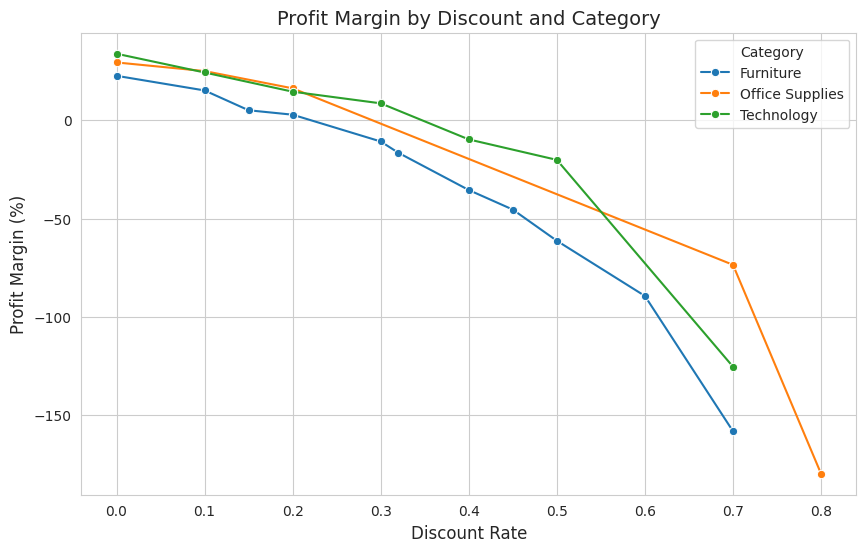

In [593]:

sns.lineplot(
    data=category_discount,
    x="Discount",
    y="Profit_Margin",
    hue="Category",
    marker="o"
)

plt.title("Profit Margin by Discount and Category")
plt.xlabel("Discount Rate")
plt.ylabel("Profit Margin (%)")
plt.show()

In [594]:
subcategory_analysis = df.groupby(
    ["Category", "Sub-Category"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

subcategory_analysis.sort_values(
    by="Total_Profit",
    ascending=True
).head(10)

,Category,Sub-Category,Total_Sales,Total_Profit,Total_Quantity
3,Furniture,Tables,206965.5320,-17725.4811,1241
0,Furniture,Bookcases,114879.9963,-3472.5560,868
12,Office Supplies,Supplies,46673.5380,-1189.0995,647
8,Office Supplies,Fasteners,3024.2800,949.5182,914
15,Technology,Machines,189238.6310,3384.7569,440
9,Office Supplies,Labels,12486.3120,5546.2540,1400
5,Office Supplies,Art,27118.7920,6527.7870,3000
7,Office Supplies,Envelopes,16476.4020,6964.1767,906
2,Furniture,Furnishings,91705.1640,13059.1436,3563
4,Office Supplies,Appliances,107532.1610,18138.0054,1729


**Deep Dive into Tables**

In [595]:
tables_analysis = df[
    df["Sub-Category"] == "Tables"
].groupby("Product Name").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Average_Discount=("Discount", "mean")
)

tables_analysis.sort_values(
    by="Total_Profit",
    ascending=True
).head(10)

,Total_Sales,Total_Profit,Total_Quantity,Average_Discount
Product Name,,,,
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,9917.6400,-2876.1156,27,0.280000
Bush Advantage Collection Racetrack Conference Table,9544.7250,-1934.3976,33,0.350000
Balt Solid Wood Round Tables,6518.7540,-1201.0581,19,0.200000
BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables,1706.2500,-1148.4375,15,0.483333
"Riverside Furniture Oval Coffee Table, Oval End Table, End Table with Drawer",4446.1750,-1147.4000,25,0.300000
Bretford “Just In Time” Height-Adjustable Multi-Task Work Tables,5634.9000,-964.1940,17,0.225000
"Bevis Oval Conference Table, Walnut",6942.0680,-856.0144,36,0.275000
BPI Conference Tables,2241.8675,-795.9725,26,0.370000
Hon 94000 Series Round Tables,7404.5000,-681.2140,30,0.160000


In [596]:
tables_analysis["Profit_Margin"] = (
    tables_analysis["Total_Profit"] /
    tables_analysis["Total_Sales"]
) * 100
tables_analysis.sort_values(
    by="Profit_Margin",
    ascending=True
)

,Total_Sales,Total_Profit,Total_Quantity,Average_Discount,Profit_Margin
Product Name,,,,,
BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables,1706.2500,-1148.4375,15,0.483333,-67.307692
Bevis Rectangular Conference Tables,1007.2620,-586.8396,13,0.475000,-58.260870
Riverside Furniture Stanwyck Manor Table Series,917.9200,-415.9325,5,0.366667,-45.312500
BPI Conference Tables,2241.8675,-795.9725,26,0.370000,-35.504886
Balt Split Level Computer Training Table,1040.6250,-357.9750,12,0.380000,-34.400000
Anderson Hickey Conga Table Tops & Accessories,51.7820,-17.5145,5,0.300000,-33.823529
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,9917.6400,-2876.1156,27,0.280000,-29.000000
Balt Solid Wood Rectangular Table,828.0965,-216.2545,11,0.262500,-26.114650
"Riverside Furniture Oval Coffee Table, Oval End Table, End Table with Drawer",4446.1750,-1147.4000,25,0.300000,-25.806452


In [597]:
print("Loss-making products:",
      (tables_analysis["Total_Profit"] < 0).sum())

print("Profitable products:",
      (tables_analysis["Total_Profit"] > 0).sum())

print("Total products:",
      len(tables_analysis))

Loss-making products: 42
Profitable products: 14
Total products: 56


In [598]:
loss_percentage = (
    (tables_analysis["Total_Profit"] < 0).mean()
) * 100

print("Loss percentage:", loss_percentage)

Loss percentage: 75.0


**Loss-making products Analysis**

In [599]:
loss_products = tables_analysis[tables_analysis["Total_Profit"] < 0]

loss_products.sort_values(
    by="Total_Profit",
    ascending=True
).head(10)

,Total_Sales,Total_Profit,Total_Quantity,Average_Discount,Profit_Margin
Product Name,,,,,
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,9917.6400,-2876.1156,27,0.280000,-29.000000
Bush Advantage Collection Racetrack Conference Table,9544.7250,-1934.3976,33,0.350000,-20.266667
Balt Solid Wood Round Tables,6518.7540,-1201.0581,19,0.200000,-18.424658
BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables,1706.2500,-1148.4375,15,0.483333,-67.307692
"Riverside Furniture Oval Coffee Table, Oval End Table, End Table with Drawer",4446.1750,-1147.4000,25,0.300000,-25.806452
Bretford “Just In Time” Height-Adjustable Multi-Task Work Tables,5634.9000,-964.1940,17,0.225000,-17.111111
"Bevis Oval Conference Table, Walnut",6942.0680,-856.0144,36,0.275000,-12.330827
BPI Conference Tables,2241.8675,-795.9725,26,0.370000,-35.504886
Hon 94000 Series Round Tables,7404.5000,-681.2140,30,0.160000,-9.200000


In [600]:
worst_5 = loss_products.nsmallest(
    5, "Total_Profit"
).index

discount_analysis = df[
    df["Product Name"].isin(worst_5)
].groupby(
    ["Product Name", "Discount"]
).agg(
    Number_of_Orders=("Order ID", "nunique"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Average_Profit=("Profit", "mean")
).reset_index()

discount_analysis.sort_values(
    by=["Product Name", "Discount"]
)


,Product Name,Discount,Number_of_Orders,Total_Sales,Total_Profit,Total_Quantity,Average_Profit
0,Balt Solid Wood Round Tables,0.00,2,3571.920,321.4728,8,160.73640
1,Balt Solid Wood Round Tables,0.40,2,2946.834,-1522.5309,11,-761.26545
2,BoxOffice By Design Rectangular and Half-Moon ...,0.45,1,721.875,-420.0000,6,-420.00000
3,BoxOffice By Design Rectangular and Half-Moon ...,0.50,2,984.375,-728.4375,9,-364.21875
4,Bush Advantage Collection Racetrack Conference...,0.00,1,3393.680,610.8624,8,610.86240
5,Bush Advantage Collection Racetrack Conference...,0.30,1,890.841,-152.7156,3,-152.71560
6,Bush Advantage Collection Racetrack Conference...,0.40,3,3054.312,-1119.9144,12,-373.30480
7,Bush Advantage Collection Racetrack Conference...,0.45,1,933.262,-458.1468,4,-458.14680
8,Bush Advantage Collection Racetrack Conference...,0.50,1,1272.630,-814.4832,6,-814.48320
9,Chromcraft Bull-Nose Wood Oval Conference Tabl...,0.00,1,1652.940,231.4116,3,231.41160


**High discounts are associated with lower profitability for these five Tables products.**

In [601]:
discount_analysis["Profit_Margin"] = (
    discount_analysis["Total_Profit"] /
    discount_analysis["Total_Sales"]
) * 100
discount_analysis

,Product Name,Discount,Number_of_Orders,Total_Sales,Total_Profit,Total_Quantity,Average_Profit,Profit_Margin
0,Balt Solid Wood Round Tables,0.00,2,3571.920,321.4728,8,160.73640,9.000000
1,Balt Solid Wood Round Tables,0.40,2,2946.834,-1522.5309,11,-761.26545,-51.666667
2,BoxOffice By Design Rectangular and Half-Moon ...,0.45,1,721.875,-420.0000,6,-420.00000,-58.181818
3,BoxOffice By Design Rectangular and Half-Moon ...,0.50,2,984.375,-728.4375,9,-364.21875,-74.000000
4,Bush Advantage Collection Racetrack Conference...,0.00,1,3393.680,610.8624,8,610.86240,18.000000
5,Bush Advantage Collection Racetrack Conference...,0.30,1,890.841,-152.7156,3,-152.71560,-17.142857
6,Bush Advantage Collection Racetrack Conference...,0.40,3,3054.312,-1119.9144,12,-373.30480,-36.666667
7,Bush Advantage Collection Racetrack Conference...,0.45,1,933.262,-458.1468,4,-458.14680,-49.090909
8,Bush Advantage Collection Racetrack Conference...,0.50,1,1272.630,-814.4832,6,-814.48320,-64.000000
9,Chromcraft Bull-Nose Wood Oval Conference Tabl...,0.00,1,1652.940,231.4116,3,231.41160,14.000000


The analysis of the 56 products in the Tables sub-category reveals that 42 products (75%) generated negative profits, while only 14 products (25%) were profitable.

A closer examination of the five products with the largest losses also shows an association between higher discount rates and lower profitability. Several products generated positive profits when no discount was applied but recorded losses at certain discount levels.

For example, *Balt Solid Wood Round Tables* generated a profit of 321.47 with no discount, compared to a loss of 1,522.53 with a 40% discount.


**Product Profitability**

In [602]:
top_profitable = product_analysis.sort_values(
    by="Total_Profit",
    ascending=False
).head(10)

top_profitable

,Total_Sales,Total_Profit,Total_Quantity,Number_of_Orders
Product Name,,,,
Canon imageCLASS 2200 Advanced Copier,61599.824,25199.9280,20,5
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.384,7753.0390,31,10
Hewlett Packard LaserJet 3310 Copier,18839.686,6983.8836,38,8
Canon PC1060 Personal Laser Copier,11619.834,4570.9347,19,4
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.895,4094.9766,12,3
Ativa V4110MDD Micro-Cut Shredder,7699.890,3772.9461,11,2
"3D Systems Cube Printer, 2nd Generation, Magenta",14299.890,3717.9714,11,2
Plantronics Savi W720 Multi-Device Wireless Headset System,9367.290,3696.2820,24,7
Ibico EPK-21 Electric Binding System,15875.916,3345.2823,13,3


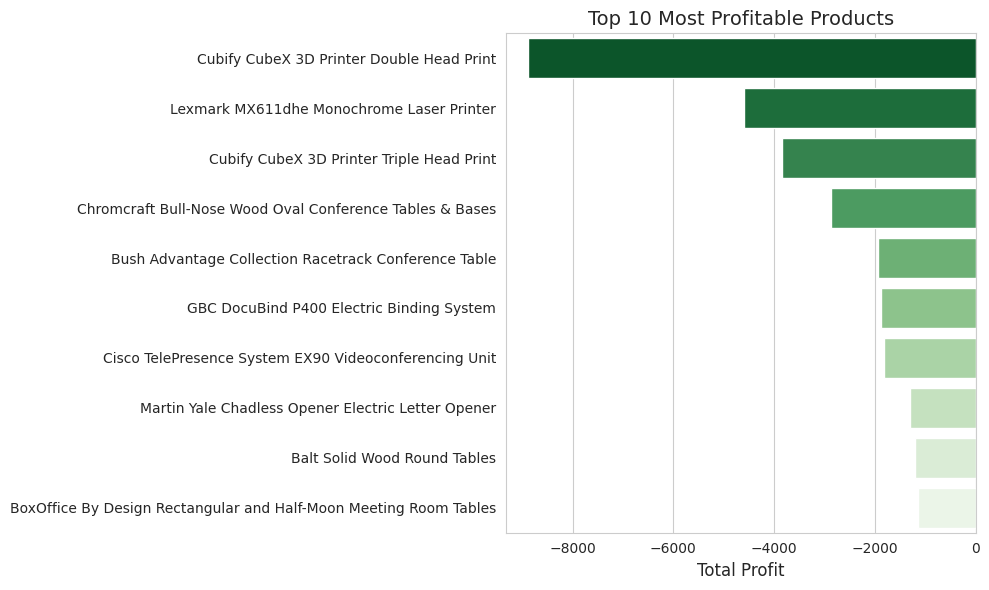

In [603]:

top_products = (df.groupby("Product Name")["Profit"]
                  .sum()
                  .sort_values(ascending=False)
                  .head(10))

plt.figure(figsize=(10, 6))
sns.barplot(
    x=worst_products.values,
    y=worst_products.index,
    hue=worst_products.index,
    palette="Greens_r",
    legend=False)
plt.title("Top 10 Most Profitable Products")
plt.xlabel("Total Profit")
plt.ylabel("")
plt.tight_layout()
plt.show()

The most profitable products generate significant absolute profit,
led by high-value Technology items such as the Canon imageCLASS copier.
These products contribute disproportionately to overall company profitability.

In [604]:
worst_products = product_analysis.sort_values(
    by="Total_Profit",
    ascending=True
).head(10)

worst_products

,Total_Sales,Total_Profit,Total_Quantity,Number_of_Orders
Product Name,,,,
Cubify CubeX 3D Printer Double Head Print,11099.963,-8879.9704,9,3
Lexmark MX611dhe Monochrome Laser Printer,16829.901,-4589.9730,18,4
Cubify CubeX 3D Printer Triple Head Print,7999.980,-3839.9904,4,1
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,9917.640,-2876.1156,27,5
Bush Advantage Collection Racetrack Conference Table,9544.725,-1934.3976,33,7
GBC DocuBind P400 Electric Binding System,17965.068,-1878.1662,27,6
Cisco TelePresence System EX90 Videoconferencing Unit,22638.480,-1811.0784,6,1
Martin Yale Chadless Opener Electric Letter Opener,16656.200,-1299.1836,22,6
Balt Solid Wood Round Tables,6518.754,-1201.0581,19,4


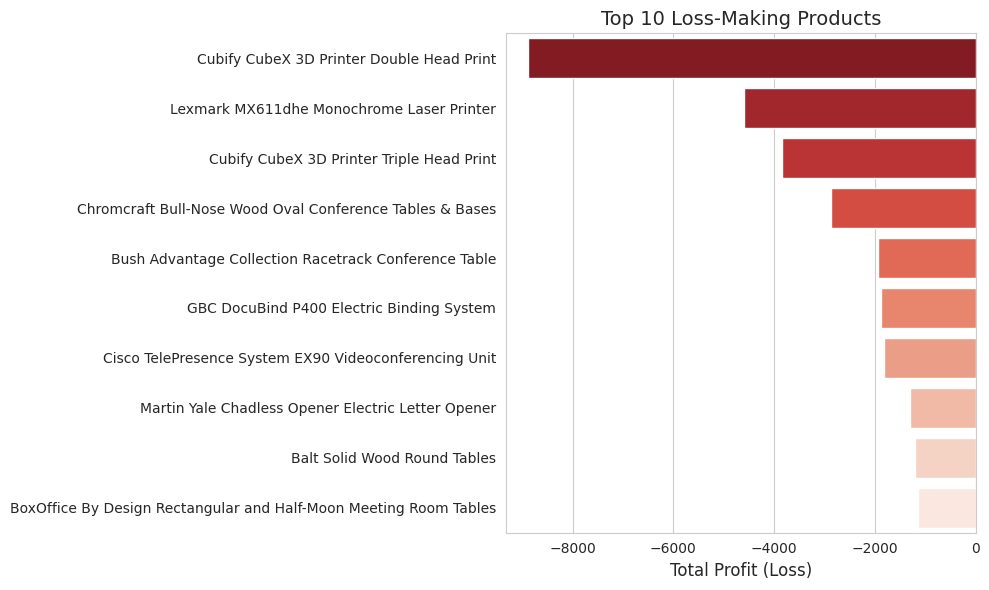

In [605]:

worst_products = (df.groupby("Product Name")["Profit"]
                    .sum()
                    .sort_values(ascending=True)
                    .head(10))

plt.figure(figsize=(10, 6))
sns.barplot(
    x=worst_products.values,
    y=worst_products.index,
    hue=worst_products.index,
    palette="Reds_r",
    legend=False
)
plt.title("Top 10 Loss-Making Products")
plt.xlabel("Total Profit (Loss)")
plt.ylabel("")
plt.tight_layout()
plt.show()

A small number of products are responsible for large absolute losses,
particularly certain printers and furniture items.
Eliminating or revising the pricing/discount strategy of these products could significantly improve overall profit.

In [606]:
product_analysis["Profit_Margin"] = (
    product_analysis["Total_Profit"] /
    product_analysis["Total_Sales"]
) * 100
product_analysis.sort_values(
    by="Profit_Margin",
    ascending=False
)

,Total_Sales,Total_Profit,Total_Quantity,Number_of_Orders,Profit_Margin
Product Name,,,,,
Canon imageCLASS MF7460 Monochrome Digital Laser Multifunction Copier,3991.980,1995.9900,2,1,50.000000
Tops Green Bar Computer Printout Paper,342.580,171.2900,7,3,50.000000
Avery 475,266.400,133.2000,18,4,50.000000
Southworth Structures Collection,72.800,36.4000,10,2,50.000000
Xerox 1890,244.700,122.3500,5,2,50.000000
...,...,...,...,...,...
Zebra GK420t Direct Thermal/Thermal Transfer Printer,703.710,-938.2800,6,1,-133.333333
Okidata B401 Printer,179.991,-251.9874,3,1,-140.000000
Euro Pro Shark Stick Mini Vacuum,170.744,-325.6332,11,3,-190.714286


The profit margin analysis of the 1,850 products highlights significant differences in product profitability.

Some products achieve high profit margins despite generating relatively low sales. For example, Southworth Structures Collection has a profit margin of 50%, but its total profit is only 36.40. In contrast, the Canon imageCLASS MF7460 generates a similar margin of 50%, with a much higher total profit of 1,995.99.

The analysis also identifies products with extremely negative profit margins. For instance, the Eureka Disposable Bags for Sanitaire Vibra Groomer I Upright Vac has the lowest profit margin (-275%), although its total loss is relatively small (-4.47).

In [607]:
product_analysis["Profit_Status"] = np.where(
    product_analysis["Total_Profit"] > 0,
    "Profitable",
    np.where(
        product_analysis["Total_Profit"] < 0,
        "Loss-making",
        "Break-even"
    )
)

product_analysis["Profit_Status"].value_counts()

,count
Profit_Status,
Profitable,1546
Loss-making,301
Break-even,3


The analysis of 1,850 products reveals that 1,546 products (83.57%) generated positive profits, while 301 products (16.27%) recorded losses. Only 3 products (0.16%) reached the break-even point.

These results indicate that the majority of products are profitable. However, the presence of 301 loss-making products highlights opportunities to improve the company's overall profitability.

In [608]:
product_analysis.groupby("Profit_Status").agg(
    Total_Sales=("Total_Sales", "sum"),
    Total_Profit=("Total_Profit", "sum"),
    Number_of_Products=("Total_Profit", "count")
)

,Total_Sales,Total_Profit,Number_of_Products
Profit_Status,,,
Break-even,5.926100e+02,0.0000,3
Loss-making,5.554145e+05,-77068.3808,301
Profitable,1.741194e+06,363465.4025,1546


### Financial Impact of Product Profitability

The financial analysis shows that the 1,546 profitable products generated a total profit of 363,465.40, while the 301 loss-making products recorded a combined loss of 77,068.38.

Although loss-making products represent only 16.27% of the product portfolio, their financial impact is significant. Their losses offset approximately 21.2% of the profits generated by profitable products.

The overall net profit across all products is 286,397.02.

**Business Recommendations:**
- Focus on reducing losses generated by underperforming products.
- Investigate the main factors affecting their profitability, particularly discounts, selling prices, and costs.
- Preserve profitable products while identifying opportunities to improve their performance.
- Prioritize products with the largest financial losses for further investigation.

**Conclusion:** The company has a largely profitable product portfolio, but reducing losses among underperforming products could significantly improve its overall profitability.

**Conclusion**

#  Final Business Insights and Recommendations

## 1. Overall Business Performance

The analysis reveals that the company generated total sales of approximately 2.30 million and a net profit of 286,397.02.

Out of 1,850 products:
- 1,546 products (83.57%) were profitable.
- 301 products (16.27%) generated losses.
- 3 products (0.16%) reached the break-even point.

Although most products are profitable, loss-making products generated a combined loss of 77,068.38, reducing the company's overall profitability.

## 2. Category Performance

Technology achieved the highest total sales (836,154.03) and total profit (145,454.95), with a profit margin of 17.40%.

Office Supplies generated the highest number of orders (6,026) and achieved a profit margin of 17.04%.

Furniture recorded 741,999.80 in sales but generated only 18,451.27 in profit, resulting in a low profit margin of 2.49%.

**Recommendation:** Maintain the strong performance of Technology and Office Supplies while investigating the low profitability of Furniture.

## 3. Product Performance

The Canon imageCLASS 2200 Advanced Copier was the most profitable product, generating 25,199.93 in total profit.

In contrast, the Cubify CubeX 3D Printer Double Head Print recorded the largest product loss, amounting to 8,879.97.

The analysis also showed that high sales do not necessarily translate into high profits.

**Recommendation:** Prioritize products according to their actual financial contribution, not sales volume alone.

## 4. Discount Analysis

The analysis revealed a negative association between discount rates and profitability, particularly in the Furniture category.

Several products recorded positive profits without discounts but generated losses at higher discount levels.

However, these findings do not establish that discounts alone cause losses. Product characteristics, costs, and order composition should also be considered.

**Recommendation:** Review discount policies and evaluate their impact on each product's profitability before applying promotional strategies.

## 5. Customer and Segment Analysis

The Consumer segment generated the highest total sales and total profit, while Home Office achieved the highest profit margin.

Customer analysis also revealed that Sean Miller generated the highest total sales among the customers examined, but recorded a negative total profit of 1,980.74.

In contrast, Tamara Chand generated the highest total profit among the customers analyzed, with 8,981.32.

**Recommendation:** Evaluate customer performance using both sales and profitability indicators. Investigate unprofitable transactions rather than relying solely on sales volume.

## 6. Regional Performance

The West region achieved the highest sales, total profit, and profit margin.

The Central region recorded the lowest profit margin, at approximately 7.92%.

**Recommendation:** Maintain the successful performance of the West region and investigate opportunities to improve profitability in the Central region.

## 7. Final Recommendations

Based on the analysis, the company should:

1. Focus on improving the profitability of loss-making products.
2. Review discount and pricing strategies, especially within Furniture.
3. Maintain and develop products that generate strong financial contributions.
4. Monitor customer profitability, not just customer sales.
5. Improve the performance of less profitable regions.
6. Use multiple performance indicators to support business decisions.

## General Conclusion

This project demonstrates that sales volume alone is not sufficient to evaluate business performance. Profitability depends on several factors, including product selection, discount policies, customer behavior, and regional performance.

By combining sales analysis with profit, profit margin, and order-level insights, the company can identify opportunities to reduce losses, improve profitability, and make more informed business decisions.